# CHB–MIT preictal analysis: corrected nonoverlapping selections

Uses the completed **30-min interictal selection-stride** runs for the −35-to−5-min preictal task. No EEG processing or model fitting is performed. The primary setting remains **R4, N=10, 60-s persistence**. Feature chunks remain 15 s with 5-s stride.

Run all cells from a fresh kernel. Outputs go to a separate nonoverlap analysis folder. Figures 6–7 retain SD bars across reservoir realizations. Primary performance CIs use 20,000 individual-cluster percentile bootstrap replicates after within-case averaging, grouping chb01/chb21 and preserving case weighting. Lead-time CIs condition on cases with defined timing.

Unavailable nonprimary runs are explicitly inventoried; this notebook cannot determine their failure causes without logs. All 120 primary R4 runs are required. Regime-level summaries average successful realizations within cases before cohort averaging. S5's BD confidence intervals also use the individual-cluster bootstrap; its colored points still display individual case–realization observations. These BD summaries condition on successful runs. The external selected-window audit establishes interval nonoverlap; this notebook does not reconstruct historical training selections.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

PROJECT = Path('/data/halders2/EEG_anomaly')
RESULT_ROOT = PROJECT / 'chbmit_preictal_35to5_nonoverlap_rossler_bd_v4_results'
ANALYSIS_DIR = PROJECT / 'chbmit_preictal_35to5_nonoverlap_rossler_bd_v4_analysis'
FIG_DIR = ANALYSIS_DIR / 'figures'
TABLE_DIR = ANALYSIS_DIR / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_REGIMES = list(range(12))
EXPECTED_RES_SEEDS = [1107, 1249, 1388, 1523, 1697]
PRIMARY_REGIME = 4
PRIMARY_PERSISTENCE = 60.0
FIG_DPI = 300

print('Results root:', RESULT_ROOT.resolve())
print('Analysis directory:', ANALYSIS_DIR.resolve())
EXPECTED_CASES = [f'chb{i:02d}' for i in range(1, 25)]
BOOTSTRAP_REPLICATES = 20000
BOOTSTRAP_SEED = 20261117


Results root: /vf/users/halders2/EEG_anomaly/chbmit_preictal_35to5_nonoverlap_rossler_bd_v4_results
Analysis directory: /vf/users/halders2/EEG_anomaly/chbmit_preictal_35to5_nonoverlap_rossler_bd_v4_analysis


In [2]:
# Load existing summaries; record empty/unreadable files explicitly.
summary_files = sorted(RESULT_ROOT.rglob('all_patient_summary.csv'))
if not summary_files:
    raise FileNotFoundError(f'No summaries under {RESULT_ROOT}')
frames, issues = [], []
for path in summary_files:
    try:
        frame = pd.read_csv(path)
        if frame.empty:
            issues.append({'file': str(path), 'problem': 'empty summary'})
            continue
        frame['source_summary_file'] = str(path)
        frames.append(frame)
    except pd.errors.EmptyDataError:
        issues.append({'file': str(path), 'problem': 'empty summary'})
    except Exception as exc:
        issues.append({'file': str(path), 'problem': repr(exc)})
issues_df = pd.DataFrame(issues, columns=['file', 'problem'])
issues_df.to_csv(TABLE_DIR / 'summary_read_issues.csv', index=False)
if issues:
    display(issues_df)
    if not issues_df['problem'].eq('empty summary').all():
        raise RuntimeError('Unreadable nonempty summaries: inspect before analysis.')
if not frames:
    raise RuntimeError('No nonempty summaries.')
raw_summary = pd.concat(frames, ignore_index=True, sort=False)
raw_summary.to_csv(ANALYSIS_DIR / 'preictal_35to5_master_summary_including_errors.csv', index=False)
error = raw_summary.get('error', pd.Series('', index=raw_summary.index))
ok = error.fillna('').astype(str).str.strip().eq('')
raw_summary.loc[~ok].to_csv(TABLE_DIR / 'reported_error_rows.csv', index=False)
df = raw_summary.loc[ok].copy()
for col in ['alarm_persistence_seconds', 'regime_id', 'res_seed', 'data_seed', 'num_reservoirs']:
    df[col] = pd.to_numeric(df[col], errors='raise')
for col in ['regime_id', 'res_seed', 'data_seed', 'num_reservoirs']:
    if df[col].isna().any() or not np.equal(df[col], np.floor(df[col])).all():
        raise ValueError(f'Invalid integer settings: {col}')
    df[col] = df[col].astype(int)
if not (df['data_seed'].eq(17).all() and df['num_reservoirs'].eq(10).all()
        and np.isclose(df['alarm_persistence_seconds'], PRIMARY_PERSISTENCE).all()):
    raise ValueError('Expected data seed 17, N=10, and 60-s persistence only.')
df.to_csv(ANALYSIS_DIR / 'preictal_35to5_master_summary.csv', index=False)
print('Summary files:', len(summary_files), '| successful rows:', len(df))
print('Empty summaries:', len(issues_df), '| reported error rows:', int((~ok).sum()))


,file,problem
0,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
1,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
2,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
3,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
4,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
5,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary
6,/data/halders2/EEG_anomaly/chbmit_preictal_35t...,empty summary


Summary files: 1440 | successful rows: 1433
Empty summaries: 7 | reported error rows: 0


In [3]:
# Explicit run inventory and validity checks before plotting.
key = ['patient', 'regime_id', 'res_seed']
if df.duplicated(key).any():
    raise ValueError('Duplicate successful case/regime/seed rows.')
expected = pd.MultiIndex.from_product(
    [EXPECTED_CASES, EXPECTED_REGIMES, EXPECTED_RES_SEEDS], names=key)
observed = pd.MultiIndex.from_frame(df[key])
if len(observed.difference(expected)):
    raise ValueError('Unexpected case/regime/seed combinations.')
run_inventory = expected.to_frame(index=False)
run_inventory['successful_summary_available'] = expected.isin(observed)
run_inventory.to_csv(TABLE_DIR / 'all_regime_run_inventory.csv', index=False)
coverage = run_inventory.groupby('regime_id')['successful_summary_available'].agg(['count', 'sum'])
coverage.columns = ['planned', 'successful']
coverage['unavailable'] = coverage['planned'] - coverage['successful']
display(coverage)
unavailable = run_inventory.loc[~run_inventory['successful_summary_available']]
if len(unavailable):
    print('UNAVAILABLE RUNS (check logs for causes):')
    display(unavailable)
if not run_inventory.loc[run_inventory['regime_id'].eq(PRIMARY_REGIME),
                         'successful_summary_available'].all():
    raise RuntimeError('Primary R4 requires all 24 cases × five seeds.')
critical = ['bd_entropy', 'bd_separated_count', 'preictal_sensitivity',
            'specificity', 'balanced_accuracy', 'false_alarms_per_hour',
            'preictal_total', 'preictal_tp', 'warning_lead_mean_seconds']
for col in critical:
    df[col] = pd.to_numeric(df[col], errors='raise')
if not np.isfinite(df[[c for c in critical if c != 'warning_lead_mean_seconds']].to_numpy()).all():
    raise ValueError('Nonfinite performance/BD values in successful rows.')
if (df['preictal_total'] <= 0).any():
    raise ValueError('No evaluated preictal events in a successful run.')
lead_defined = df['warning_lead_mean_seconds'].notna()
if not lead_defined.eq(df['preictal_tp'].gt(0)).all():
    raise ValueError('Lead-time availability disagrees with detected-event counts.')
if not np.isfinite(df.loc[lead_defined, 'warning_lead_mean_seconds']).all():
    raise ValueError('Invalid lead times.')
df['warning_lead_mean_minutes'] = df['warning_lead_mean_seconds'] / 60
sat = df['bd_saturated'].astype(str).str.lower().str.strip()
if not sat.isin(['true', 'false', '1', '0', '1.0', '0.0']).all():
    raise ValueError('Unrecognized BD saturation flags.')
df['bd_saturated'] = sat.isin(['true', '1', '1.0'])
model_df = df.copy()
model_df.to_csv(TABLE_DIR / 'bd_unique_model_runs.csv', index=False)
print('BD-saturated successful runs:', int(model_df['bd_saturated'].sum()))

def cluster_mean_ci(frame, value_col):
    # Resample independent individuals, retaining both cases when their
    # shared individual is drawn. Compute the mean over retained case values.
    x = frame[['patient', value_col]].copy()
    if x['patient'].duplicated().any():
        raise ValueError('Bootstrap requires one value per recording case.')
    x[value_col] = pd.to_numeric(x[value_col], errors='raise')
    x = x.dropna(subset=[value_col])
    if x.empty or not np.isfinite(x[value_col]).all():
        raise ValueError(f'No valid finite observations: {value_col}')
    x['individual'] = x['patient'].replace({'chb01': 'chb01_chb21', 'chb21': 'chb01_chb21'})
    grouped = x.groupby('individual')[value_col].agg(['sum', 'count'])
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    draws = rng.integers(0, len(grouped), size=(BOOTSTRAP_REPLICATES, len(grouped)))
    boot = grouped['sum'].to_numpy()[draws].sum(axis=1) / grouped['count'].to_numpy()[draws].sum(axis=1)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return dict(n_cases=len(x), n_individuals=len(grouped), mean=x[value_col].mean(),
                ci95_lower=lo, ci95_upper=hi, bootstrap_replicates=BOOTSTRAP_REPLICATES)


,planned,successful,unavailable
regime_id,,,
0,120,120,0
1,120,120,0
2,120,120,0
3,120,120,0
4,120,120,0
5,120,120,0
6,120,114,6
7,120,119,1
8,120,120,0


UNAVAILABLE RUNS (check logs for causes):


,patient,regime_id,res_seed,successful_summary_available
871,chb15,6,1249,False
1050,chb18,6,1107,False
1053,chb18,6,1523,False
1054,chb18,6,1697,False
1059,chb18,7,1697,False
1170,chb20,6,1107,False
1174,chb20,6,1697,False


BD-saturated successful runs: 0


In [4]:
# Primary long-horizon preictal configuration: R4, 60-s persistence.
primary = df.loc[
    (df['regime_id'] == PRIMARY_REGIME) &
    (df['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE)
].copy()

print('Primary regime:', f'R{PRIMARY_REGIME}')
print('Persistence:', PRIMARY_PERSISTENCE, 's')
print('Rows:', len(primary))
print('Patients:', primary['patient'].nunique())
print('Seeds:', sorted(primary['res_seed'].dropna().astype(int).unique().tolist()))

patient_primary = (
    primary.groupby('patient', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        warning_lead_mean_seconds=('warning_lead_mean_seconds', 'mean'),
        preictal_total=('preictal_total', 'mean'),
        preictal_tp=('preictal_tp', 'mean'),
        interictal_test_scans=('interictal_test_scans', 'mean'),
        interictal_fp_scans=('interictal_fp_scans', 'mean'),
    )
)

patient_primary['interictal_fp_fraction'] = (
    patient_primary['interictal_fp_scans'] /
    patient_primary['interictal_test_scans']
)
patient_primary['warning_lead_mean_minutes'] = patient_primary['warning_lead_mean_seconds'] / 60.0

# Same patient order is reused in all main figures.
patient_primary = patient_primary.sort_values(
    ['preictal_sensitivity', 'specificity'],
    ascending=[False, False]
).reset_index(drop=True)

display(patient_primary)
patient_primary.to_csv(TABLE_DIR / 'primary_R4_60s_patient_summary.csv', index=False)

Primary regime: R4
Persistence: 60.0 s
Rows: 120
Patients: 24
Seeds: [1107, 1249, 1388, 1523, 1697]


,patient,preictal_sensitivity,specificity,balanced_accuracy,false_alarms_per_hour,warning_lead_mean_seconds,preictal_total,preictal_tp,interictal_test_scans,interictal_fp_scans,interictal_fp_fraction,warning_lead_mean_minutes
0,chb19,1.000000,0.857143,0.928571,0.342857,1685.500000,2.0,2.0,14.0,2.0,0.142857,28.091667
1,chb15,1.000000,0.769231,0.884615,0.492308,2025.000000,1.0,1.0,13.0,3.0,0.230769,33.750000
2,chb11,1.000000,0.637500,0.818750,1.025000,2025.000000,1.0,1.0,16.0,5.8,0.362500,33.750000
3,chb16,1.000000,0.300000,0.650000,2.133333,2025.000000,1.0,1.0,6.0,4.2,0.700000,33.750000
4,chb13,0.900000,0.416667,0.658333,1.300000,1768.500000,2.0,1.8,12.0,7.0,0.583333,29.475000
5,chb07,0.866667,0.760000,0.813333,0.626667,1806.666667,3.0,2.6,30.0,7.2,0.240000,30.111111
6,chb08,0.850000,0.675000,0.762500,0.950000,1886.833333,4.0,3.4,8.0,2.6,0.325000,31.447222
7,chb18,0.500000,1.000000,0.750000,0.000000,1980.000000,2.0,1.0,15.0,0.0,0.000000,33.000000
8,chb02,0.500000,0.882353,0.691176,0.400000,663.000000,2.0,1.0,17.0,2.0,0.117647,11.050000
9,chb23,0.500000,0.550000,0.525000,0.950000,1832.000000,4.0,2.0,8.0,3.6,0.450000,30.533333


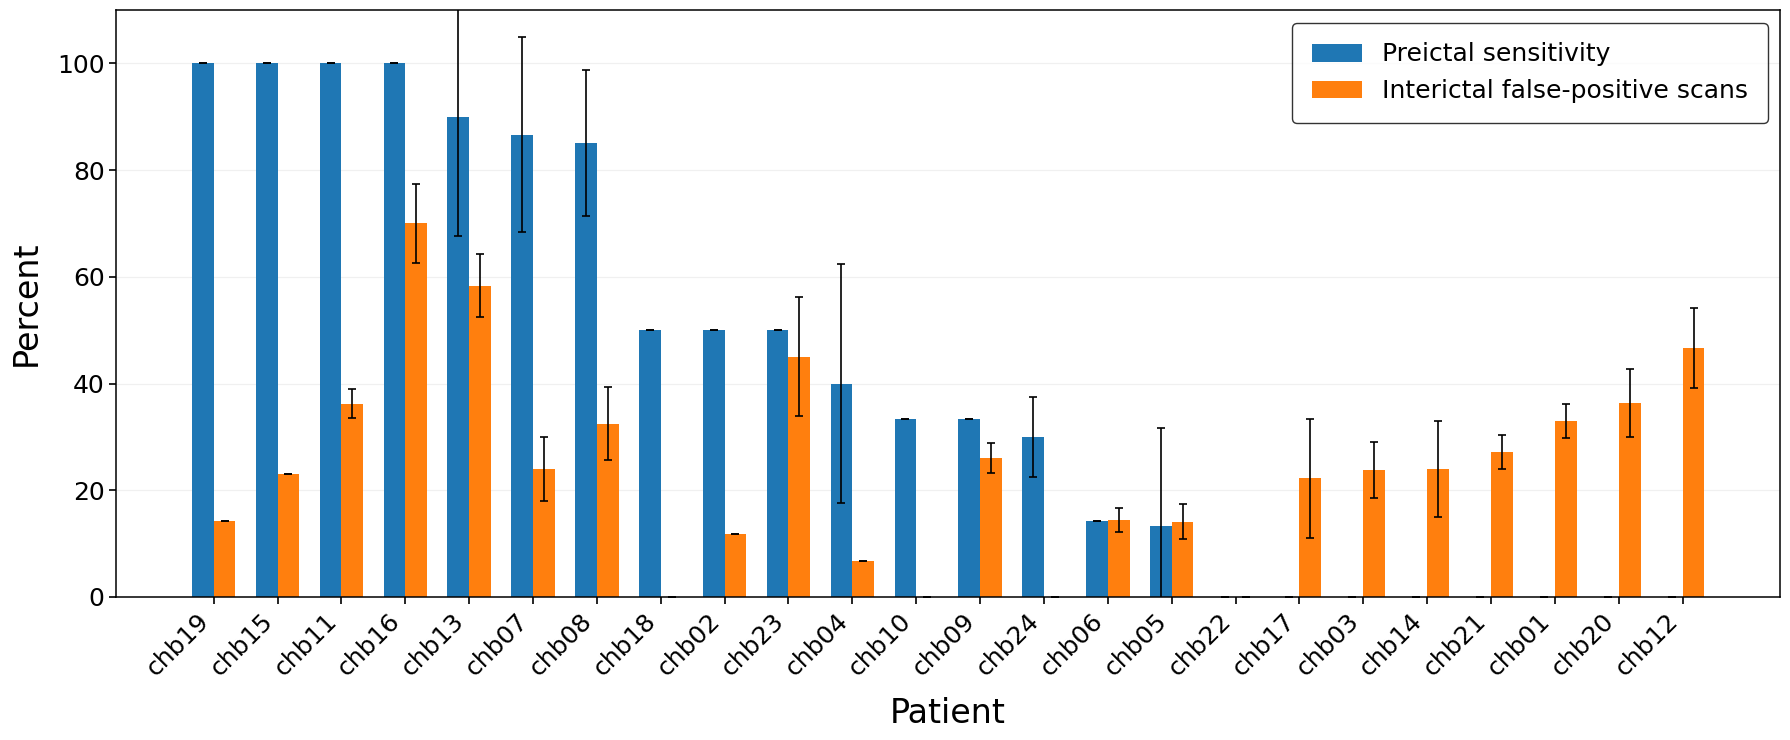

In [5]:
# MAIN FIGURE 1: patient-wise preictal sensitivity and interictal false-positive scan fraction
# with SD error bars across reservoir seeds.

patient_plot = (
    primary.groupby('patient', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        preictal_sensitivity_sd=('preictal_sensitivity', 'std'),
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),
    )
)

patient_plot['interictal_fp_fraction'] = 1.0 - patient_plot['specificity']

# Because FP fraction = 1 - specificity, the SD is the same
patient_plot['interictal_fp_fraction_sd'] = patient_plot['specificity_sd']

# Preserve the exact patient order already used in patient_primary
patient_plot = (
    patient_primary[['patient']]
    .merge(patient_plot, on='patient', how='left')
)

x = np.arange(len(patient_plot))
width = 0.34

sens_pct = 100 * patient_plot['preictal_sensitivity'].to_numpy()
sens_sd_pct = 100 * patient_plot['preictal_sensitivity_sd'].fillna(0).to_numpy()

fp_pct = 100 * patient_plot['interictal_fp_fraction'].to_numpy()
fp_sd_pct = 100 * patient_plot['interictal_fp_fraction_sd'].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(18, 7.5))

ax.bar(
    x - width/2,
    sens_pct,
    width,
    yerr=sens_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Preictal sensitivity'
)

ax.bar(
    x + width/2,
    fp_pct,
    width,
    yerr=fp_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Interictal false-positive scans'
)

ax.set_ylabel('Percent', fontsize=24, labelpad=10)
ax.set_xlabel('Patient', fontsize=24, labelpad=12)

ax.set_xticks(x)
ax.set_xticklabels(
    patient_plot['patient'],
    rotation=45,
    ha='right',
    fontsize=18
)

ax.tick_params(axis='y', labelsize=18, width=1.2, length=5)
ax.tick_params(axis='x', width=1.2, length=5)

ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.18, linewidth=0.9)
ax.set_axisbelow(True)

leg = ax.legend(
    frameon=True,
    fontsize=18,
    loc='upper right',
    borderpad=0.8
)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.0)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_preictal_fig1_patient_detection.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

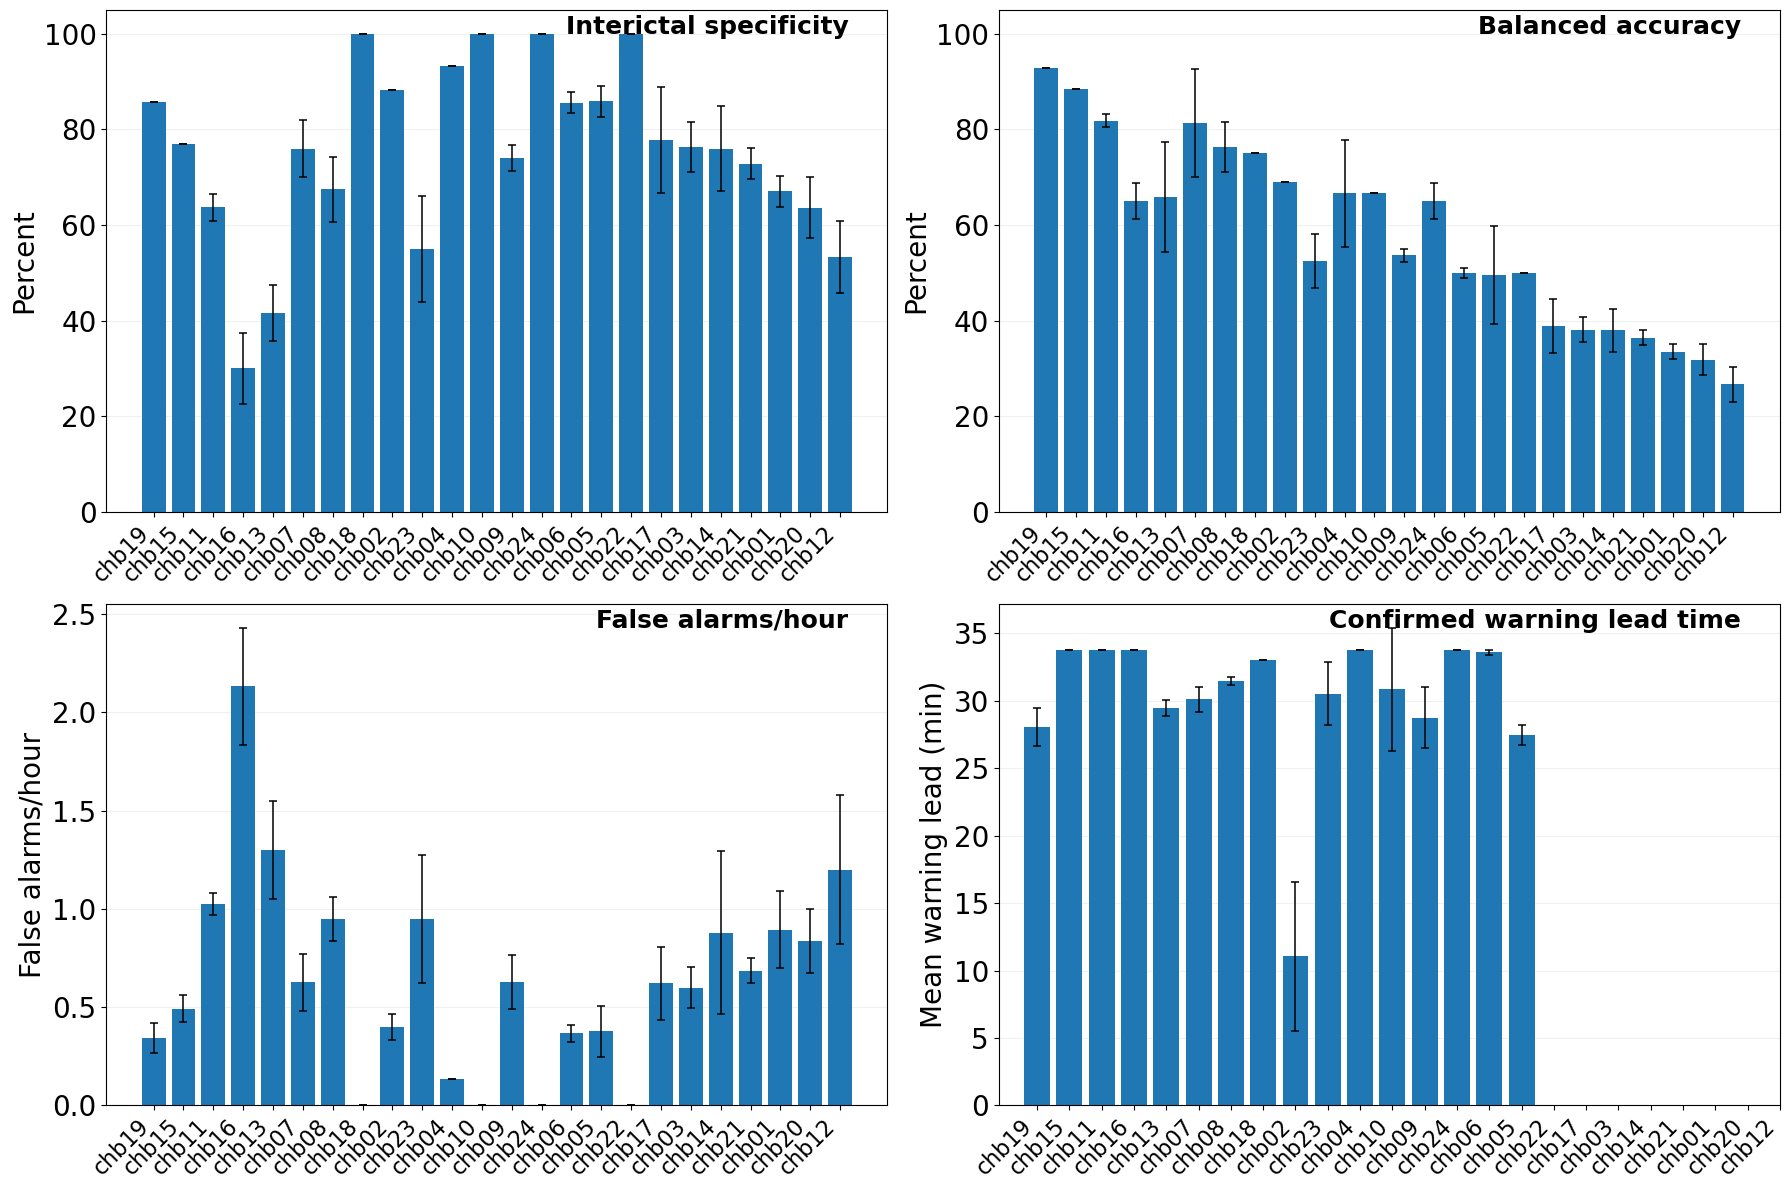

In [6]:
# MAIN FIGURE 2: patient-wise specificity, balanced accuracy, FAR/h,
# and warning lead time with SD error bars across reservoir seeds.

patient_metrics = (
    primary.groupby('patient', as_index=False)
    .agg(
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),

        balanced_accuracy=('balanced_accuracy', 'mean'),
        balanced_accuracy_sd=('balanced_accuracy', 'std'),

        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        false_alarms_per_hour_sd=('false_alarms_per_hour', 'std'),

        warning_lead_mean_minutes=('warning_lead_mean_minutes', 'mean'),
        warning_lead_mean_minutes_sd=('warning_lead_mean_minutes', 'std'),
    )
)

# Preserve exactly the same patient order as patient_primary
patient_metrics = (
    patient_primary[['patient']]
    .merge(patient_metrics, on='patient', how='left')
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
x = np.arange(len(patient_metrics))

panels = [
    (
        'specificity',
        'specificity_sd',
        'Interictal specificity',
        100.0,
        'Percent',
        (0, 105)
    ),
    (
        'balanced_accuracy',
        'balanced_accuracy_sd',
        'Balanced accuracy',
        100.0,
        'Percent',
        (0, 105)
    ),
    (
        'false_alarms_per_hour',
        'false_alarms_per_hour_sd',
        'False alarms/hour',
        1.0,
        'False alarms/hour',
        None
    ),
    (
        'warning_lead_mean_minutes',
        'warning_lead_mean_minutes_sd',
        'Confirmed warning lead time',
        1.0,
        'Mean warning lead (min)',
        None
    ),
]

for ax, (col, sd_col, panel_label, scale, ylabel, ylim) in zip(axes.flat, panels):

    vals = scale * patient_metrics[col].to_numpy()
    errs = scale * patient_metrics[sd_col].fillna(0).to_numpy()

    ax.bar(
        x,
        vals,
        yerr=errs,
        capsize=3,
        error_kw={
            'elinewidth': 1.1,
            'capthick': 1.1
        }
    )

    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_xticks(x)
    ax.set_xticklabels(
        patient_metrics['patient'],
        rotation=45,
        ha='right',
        fontsize=16
    )

    ax.tick_params(axis='y', labelsize=20)
    ax.grid(axis='y', alpha=0.18, linewidth=0.8)
    ax.set_axisbelow(True)

    ax.text(
        0.95, 0.99,
        panel_label,
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=18,
        fontweight='bold'
    )

    if ylim is not None:
        ax.set_ylim(*ylim)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_preictal_fig2_patient_metrics.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

In [7]:
# Cohort summary for the primary R4 / 60-s preictal configuration.
def summarize_metric(name, series):
    s = pd.to_numeric(series, errors='coerce').dropna()
    return {
        'metric': name,
        'n_patients': len(s),
        'mean': s.mean(),
        'sd': s.std(),
        'median': s.median(),
        'q25': s.quantile(0.25),
        'q75': s.quantile(0.75),
        'min': s.min(),
        'max': s.max(),
    }

primary_summary = pd.DataFrame([
    summarize_metric('preictal_sensitivity', patient_primary['preictal_sensitivity']),
    summarize_metric('specificity', patient_primary['specificity']),
    summarize_metric('balanced_accuracy', patient_primary['balanced_accuracy']),
    summarize_metric('false_alarms_per_hour', patient_primary['false_alarms_per_hour']),
    summarize_metric('warning_lead_minutes', patient_primary['warning_lead_mean_minutes']),
])

display(primary_summary)
primary_summary.to_csv(TABLE_DIR / 'primary_R4_60s_cohort_summary.csv', index=False)

,metric,n_patients,mean,sd,median,q25,q75,min,max
0,preictal_sensitivity,24,0.406647,0.394271,0.333333,0.000000,0.854167,0.000000,1.000000
1,specificity,24,0.754383,0.183604,0.761250,0.662316,0.864706,0.300000,1.000000
2,balanced_accuracy,24,0.580515,0.191704,0.593333,0.386979,0.705882,0.266667,0.928571
3,false_alarms_per_hour,24,0.643461,0.497416,0.624444,0.361714,0.908088,0.000000,2.133333
4,warning_lead_minutes,16,30.196354,5.573427,31.152778,29.293750,33.750000,11.050000,33.750000


In [8]:
# Primary corrected preictal performance with 95% CIs.
ci_columns = {
    'Sensitivity': 'preictal_sensitivity',
    'Specificity': 'specificity',
    'Balanced accuracy': 'balanced_accuracy',
    'False-alarm episodes/hour': 'false_alarms_per_hour',
    'Warning lead time (minutes)': 'warning_lead_mean_minutes',
}
preictal_ci = pd.DataFrame([
    {'metric': label, **cluster_mean_ci(patient_primary, col)}
    for label, col in ci_columns.items()
])
print('PRIMARY NONOVERLAPPING PREICTAL RESULTS WITH 95% CIs')
print(preictal_ci.to_string(index=False))
preictal_ci.to_csv(TABLE_DIR / 'preictal_R4_60s_cluster_bootstrap_CI.csv', index=False)
print('Eligible events, counted once per case:', int(patient_primary['preictal_total'].sum()))


PRIMARY NONOVERLAPPING PREICTAL RESULTS WITH 95% CIs
                     metric  n_cases  n_individuals      mean  ci95_lower  ci95_upper  bootstrap_replicates
                Sensitivity       24             23  0.406647    0.253175    0.572155                 20000
                Specificity       24             23  0.754383    0.680921    0.825535                 20000
          Balanced accuracy       24             23  0.580515    0.503350    0.659890                 20000
  False-alarm episodes/hour       24             23  0.643461    0.454888    0.845035                 20000
Warning lead time (minutes)       16             16 30.196354   27.182096   32.280564                 20000
Eligible events, counted once per case: 64


In [9]:
# S5: case-weighted BD means and individual-cluster bootstrap CIs.
bd_cases = model_df.groupby(['patient', 'regime_id'], as_index=False)['bd_entropy'].mean()
bd_rows = []
for rid, g in bd_cases.groupby('regime_id'):
    stats = cluster_mean_ci(g, 'bd_entropy')
    seed_rows = model_df.loc[model_df['regime_id'].eq(rid)]
    bd_rows.append(dict(regime_id=rid, bd_mean=stats['mean'],
                        bd_ci95_lower=stats['ci95_lower'], bd_ci95_upper=stats['ci95_upper'],
                        n_cases=stats['n_cases'], n_individuals=stats['n_individuals'],
                        n_successful_realizations=len(seed_rows),
                        saturated=int(seed_rows['bd_saturated'].sum())))
bd_regime = pd.DataFrame(bd_rows)
REGIME_ORDER_BD = bd_regime.sort_values(['bd_mean', 'regime_id'])['regime_id'].astype(int).tolist()
print('Regime order by mean BD entropy:', REGIME_ORDER_BD)
display(bd_regime.sort_values('bd_mean'))
bd_regime.to_csv(TABLE_DIR / 'bd_by_regime.csv', index=False)


Regime order by mean BD entropy: [4, 3, 2, 9, 8, 1, 0, 7, 6, 5, 10, 11]


,regime_id,bd_mean,bd_ci95_lower,bd_ci95_upper,n_cases,n_individuals,n_successful_realizations,saturated
4,4,0.032170,0.030453,0.033921,24,23,120,0
3,3,0.032344,0.030555,0.034191,24,23,120,0
2,2,0.032362,0.030593,0.034167,24,23,120,0
9,9,0.032566,0.030767,0.034403,24,23,120,0
8,8,0.032649,0.030836,0.034498,24,23,120,0
1,1,0.033002,0.031224,0.034786,24,23,120,0
0,0,0.033562,0.031720,0.035361,24,23,120,0
7,7,0.034049,0.032090,0.035984,24,23,119,0
6,6,0.034540,0.032516,0.036518,24,23,114,0
5,5,0.035216,0.033345,0.037123,24,23,120,0


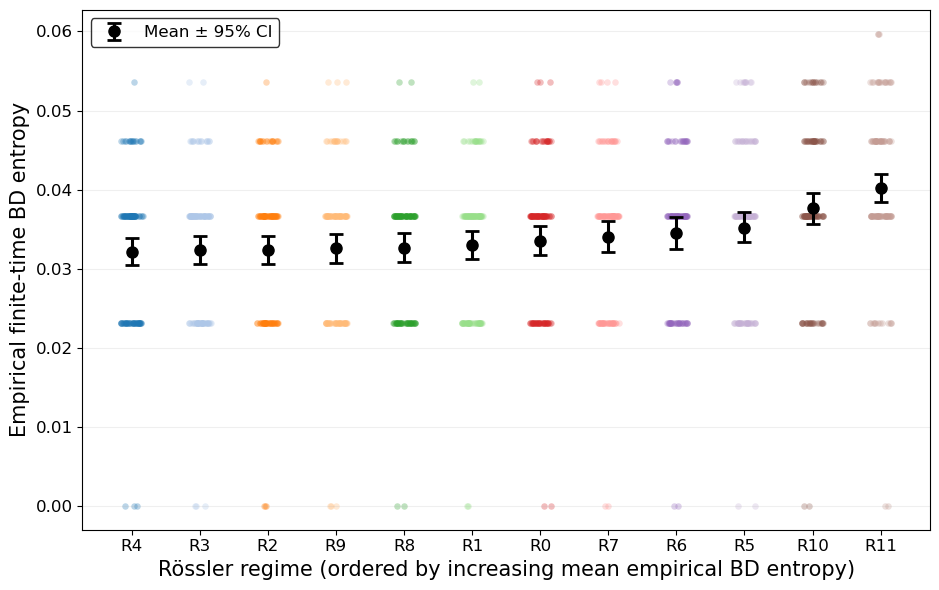

In [10]:
# SUPPLEMENTARY FIGURE: empirical BD entropy across the 12 regimes.
fig, ax = plt.subplots(figsize=(9.5, 6.0))
rng = np.random.default_rng(17)
plot_order = REGIME_ORDER_BD
xpos = np.arange(len(plot_order))
cmap = plt.get_cmap('tab20')

for i, (x, rid) in enumerate(zip(xpos, plot_order)):
    vals = model_df.loc[model_df['regime_id'] == rid, 'bd_entropy'].dropna().to_numpy()
    jitter = rng.uniform(-0.16, 0.16, size=len(vals))
    ax.scatter(np.full(len(vals), x) + jitter, vals, s=22, alpha=0.30,
               color=cmap(i % 20), linewidths=0, zorder=1)

bd_plot = bd_regime.set_index('regime_id').loc[plot_order].reset_index()
ax.errorbar(
    xpos, bd_plot['bd_mean'], yerr=np.vstack([bd_plot['bd_mean'] - bd_plot['bd_ci95_lower'],
                    bd_plot['bd_ci95_upper'] - bd_plot['bd_mean']]),
    fmt='o', color='black', ecolor='black', markerfacecolor='black',
    markeredgecolor='black', markersize=8, elinewidth=2.2, capsize=5,
    capthick=2.0, label='Mean ± 95% CI', zorder=3
)
ax.set_xlabel('Rössler regime (ordered by increasing mean empirical BD entropy)', fontsize=15)
ax.set_ylabel('Empirical finite-time BD entropy', fontsize=15)
ax.set_xticks(xpos)
ax.set_xticklabels([f'R{rid}' for rid in plot_order], fontsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis='y', alpha=0.20, linewidth=0.8)
leg = ax.legend(frameon=True, fontsize=12, loc='upper left')
leg.get_frame().set_edgecolor('black')
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_bd_entropy_by_regime.{ext}', bbox_inches='tight', **kwargs)
plt.show()

In [11]:
# Patient-wise BD--performance associations at the primary 60-s persistence setting.
# Five reservoir realizations are averaged within each patient × regime first.
preictal_60 = df.loc[df['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE].copy()

patient_regime = (
    preictal_60.groupby(['patient', 'regime_id'], as_index=False)
    .agg(
        bd_entropy=('bd_entropy', 'mean'),
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('false_alarms_per_hour', 'mean'),
        warning_lead_minutes=('warning_lead_mean_seconds', lambda s: pd.to_numeric(s, errors='coerce').mean() / 60.0),
    )
)

metrics = [
    ('preictal_sensitivity', 'Preictal sensitivity'),
    ('specificity', 'Interictal specificity'),
    ('balanced_accuracy', 'Balanced accuracy'),
    ('far_per_hour', 'False alarms/hour'),
    ('warning_lead_minutes', 'Warning lead time'),
]

rows = []
for patient, g in patient_regime.groupby('patient'):
    for metric, label in metrics:
        valid = g[['bd_entropy', metric]].dropna()
        if len(valid) >= 3 and valid['bd_entropy'].nunique() >= 2 and valid[metric].nunique() >= 2:
            rho, pval = spearmanr(valid['bd_entropy'], valid[metric])
        else:
            rho, pval = np.nan, np.nan
        rows.append({
            'patient': patient, 'metric': metric, 'metric_label': label,
            'n_regimes': len(valid), 'spearman_rho': rho, 'spearman_p': pval
        })

patient_corr = pd.DataFrame(rows)
display(patient_corr)
patient_corr.to_csv(TABLE_DIR / 'patientwise_bd_performance_spearman_60s.csv', index=False)

,patient,metric,metric_label,n_regimes,spearman_rho,spearman_p
0,chb01,preictal_sensitivity,Preictal sensitivity,12,NaN,NaN
1,chb01,specificity,Interictal specificity,12,0.215410,0.501347
2,chb01,balanced_accuracy,Balanced accuracy,12,0.215819,0.500514
3,chb01,far_per_hour,False alarms/hour,12,-0.391965,0.207613
4,chb01,warning_lead_minutes,Warning lead time,0,NaN,NaN
...,...,...,...,...,...,...
115,chb24,preictal_sensitivity,Preictal sensitivity,12,0.143125,0.657222
116,chb24,specificity,Interictal specificity,12,NaN,NaN
117,chb24,balanced_accuracy,Balanced accuracy,12,0.142769,0.658030
118,chb24,far_per_hour,False alarms/hour,12,NaN,NaN


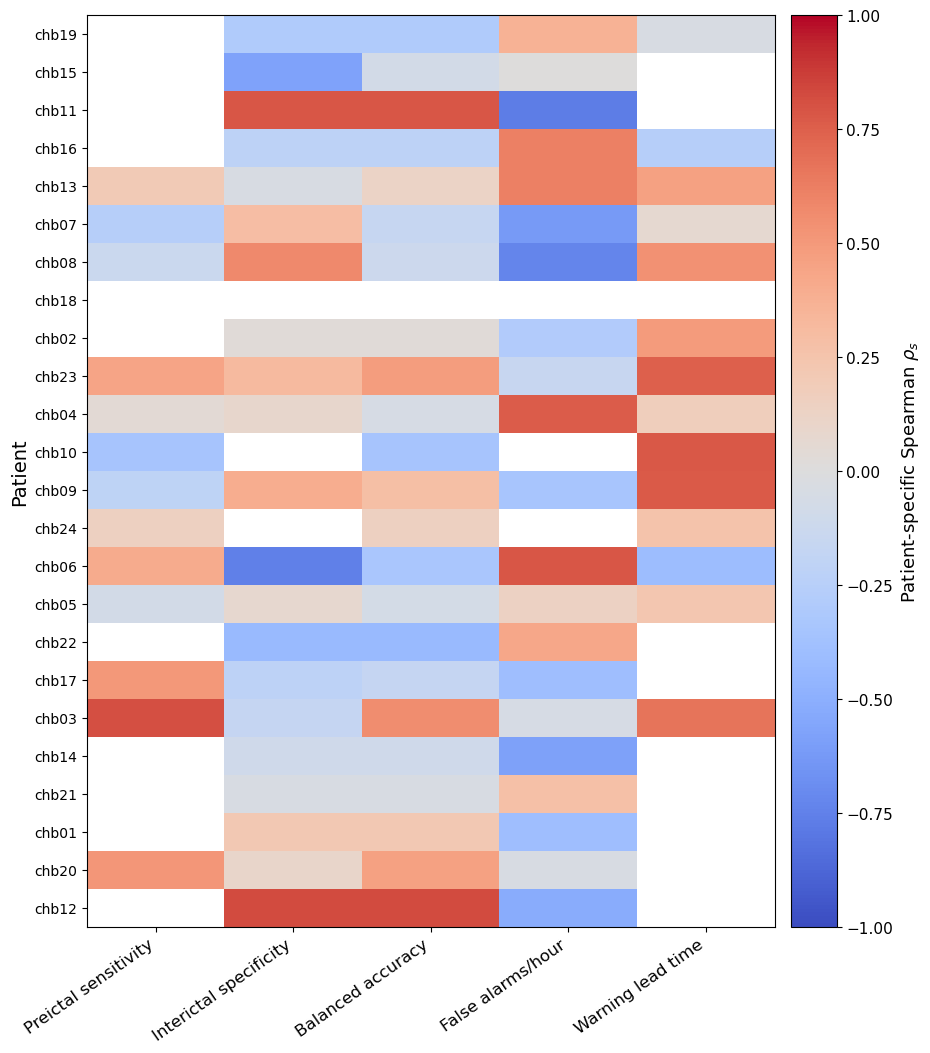

In [12]:
# SUPPLEMENTARY FIGURE: heatmap of patient-specific BD--performance Spearman correlations.
heat = patient_corr.pivot(index='patient', columns='metric_label', values='spearman_rho')
# Order patients by preictal sensitivity from Main Fig. 1.
patient_order = patient_primary['patient'].tolist()
heat = heat.reindex(patient_order)
col_order = [label for _, label in metrics]
heat = heat.reindex(columns=col_order)

fig, ax = plt.subplots(figsize=(9.5, max(7.0, 0.36 * len(heat) + 2.0)))
im = ax.imshow(heat.to_numpy(dtype=float), aspect='auto', vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(np.arange(len(col_order)))
ax.set_xticklabels(col_order, rotation=35, ha='right', fontsize=12)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index, fontsize=10)
ax.set_ylabel('Patient', fontsize=14)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(r'Patient-specific Spearman $\rho_s$', fontsize=13)
cbar.ax.tick_params(labelsize=11)
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_patientwise_bd_correlations.{ext}', bbox_inches='tight', **kwargs)
plt.show()

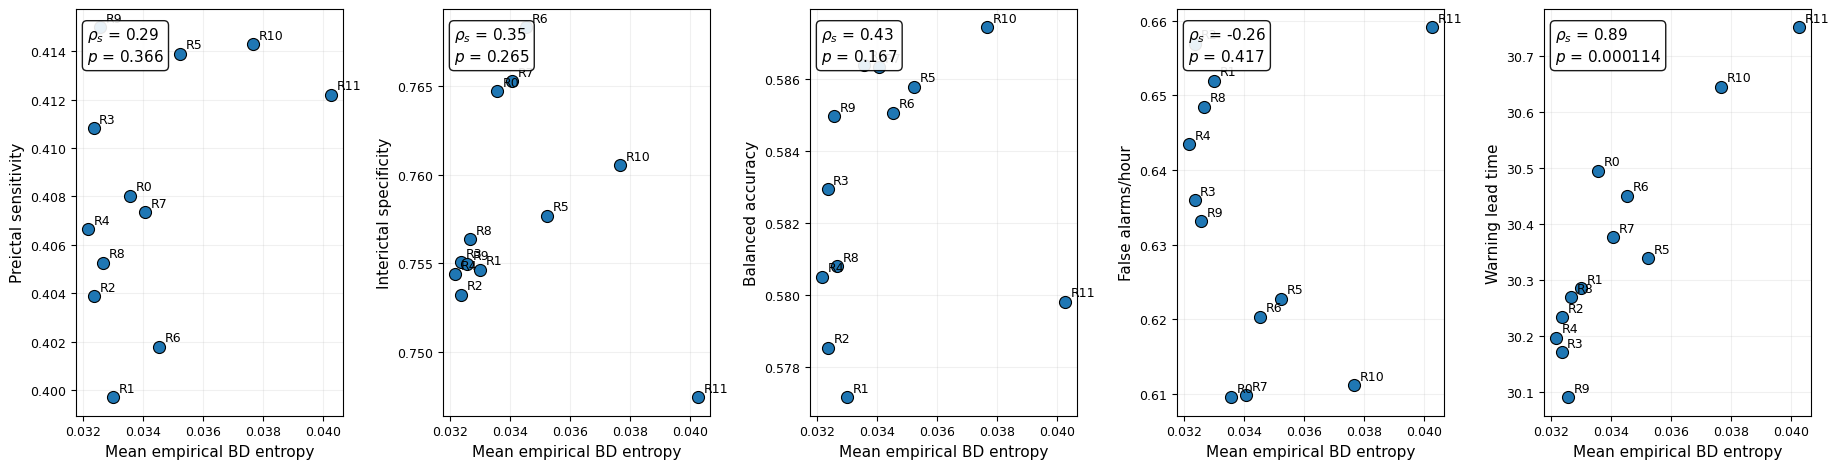

,regime_id,preictal_sensitivity,specificity,balanced_accuracy,far_per_hour,warning_lead_minutes,bd_mean
0,4,0.406647,0.754383,0.580515,0.643461,30.196354,0.032170
1,3,0.410813,0.755061,0.582937,0.635971,30.170139,0.032344
2,2,0.403869,0.753218,0.578543,0.656853,30.232899,0.032362
3,9,0.414980,0.754934,0.584957,0.633127,30.090104,0.032566
4,8,0.405258,0.756348,0.580803,0.648469,30.268142,0.032649
5,1,0.399702,0.754643,0.577173,0.651933,30.284635,0.033002
6,0,0.408036,0.764723,0.586380,0.609591,30.494526,0.033562
7,7,0.407341,0.765283,0.586312,0.609873,30.375654,0.034049
8,6,0.401786,0.768324,0.585055,0.620360,30.449918,0.034540
9,5,0.413889,0.757668,0.585779,0.622784,30.338399,0.035216


REGIME-LEVEL BD ASSOCIATIONS (exploratory, unadjusted p-values)


,metric,n_regimes,spearman_rho,p_value
0,preictal_sensitivity,12,0.286713,0.366251
1,specificity,12,0.349650,0.265239
2,balanced_accuracy,12,0.426573,0.166700
3,far_per_hour,12,-0.258741,0.416775
4,warning_lead_minutes,12,0.888112,0.000114


In [13]:
# SUPPLEMENTARY FIGURE: regime-level mean BD entropy versus preictal performance.
perf_regime_60 = (
    patient_regime.groupby('regime_id', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('far_per_hour', 'mean'),
        warning_lead_minutes=('warning_lead_minutes', 'mean'),
    )
    .merge(bd_regime[['regime_id', 'bd_mean']], on='regime_id', how='inner')
    .sort_values('bd_mean')
    .reset_index(drop=True)
)

regime_correlation_rows = []
fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.8), sharex=True)
for ax, (metric, ylabel) in zip(axes, metrics):
    ax.scatter(perf_regime_60['bd_mean'], perf_regime_60[metric],
               s=75, edgecolor='black', linewidth=0.8, zorder=3)
    for _, row in perf_regime_60.iterrows():
        ax.annotate(f"R{int(row['regime_id'])}", (row['bd_mean'], row[metric]),
                    xytext=(4, 4), textcoords='offset points', fontsize=9)
    valid = perf_regime_60[['bd_mean', metric]].dropna()
    if len(valid) >= 3 and valid['bd_mean'].nunique() >= 2 and valid[metric].nunique() >= 2:
        rho, pval = spearmanr(valid['bd_mean'], valid[metric])
        txt = rf'$\rho_s$ = {rho:.2f}' + '\n' + rf'$p$ = {pval:.3g}'
    else:
        txt = 'Correlation undefined'
    regime_correlation_rows.append({'metric': metric, 'n_regimes': len(valid),
                                    'spearman_rho': rho if txt != 'Correlation undefined' else np.nan,
                                    'p_value': pval if txt != 'Correlation undefined' else np.nan})
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, ha='left', va='top', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black', alpha=0.9))
    ax.set_xlabel('Mean empirical BD entropy', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(alpha=0.18, linewidth=0.8)

fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_regime_level_performance_vs_bd.{ext}', bbox_inches='tight', **kwargs)
plt.show()

display(perf_regime_60)
perf_regime_60.to_csv(TABLE_DIR / 'preictal_60s_regime_performance_vs_bd.csv', index=False)
regime_correlations = pd.DataFrame(regime_correlation_rows)
print('REGIME-LEVEL BD ASSOCIATIONS (exploratory, unadjusted p-values)')
display(regime_correlations)
regime_correlations.to_csv(TABLE_DIR / 'preictal_regime_level_bd_correlations.csv', index=False)
